# 16 · Technology crossovers

When did one technology overtake another, and does the date hold up inside the control sources?

**Method.** A *crossover* is the first period after which technology A stays ahead of technology B for every later period. Shares are of tech-naming postings (the unique IT postings with a description that name at least one technology), per period (years to 2022, quarters from 2023). The all-source line can cross because the source mix changed, so a crossover is called a finding only when it also happens inside **both** control sources, LinkedIn and Monster Asia, within two quarters of each other. Monster Asia is small, so the usual 400-posting floor per period is lowered to 100 here and the "stays ahead for good" rule does the protecting. A technology must lead by at least 2 points (`LEAD_MARGIN`) to count as ahead, because a half-point lead is a tie, not a crossover. A crossover in the last two quarters has too little time behind it to call and is flagged as such.

In [1]:
from vnjobs.analysis import core as a
from vnjobs.analysis import crossovers as c
from vnjobs.analysis import technologies as t

a.apply_style()
con = a.connect()
df = a.load_features(con)
named = t.naming_postings(df)
series = c.series_by_scope(named)
a.save_table(series.drop(columns="period_date"), "16-technology-series-by-scope")
print(f"{len(named):,} tech-naming postings")
series.groupby("scope").period.nunique()

88,319 tech-naming postings


scope
All sources     18
LinkedIn        14
Monster Asia    13
Name: period, dtype: int64

## 1. The pairs, drawn

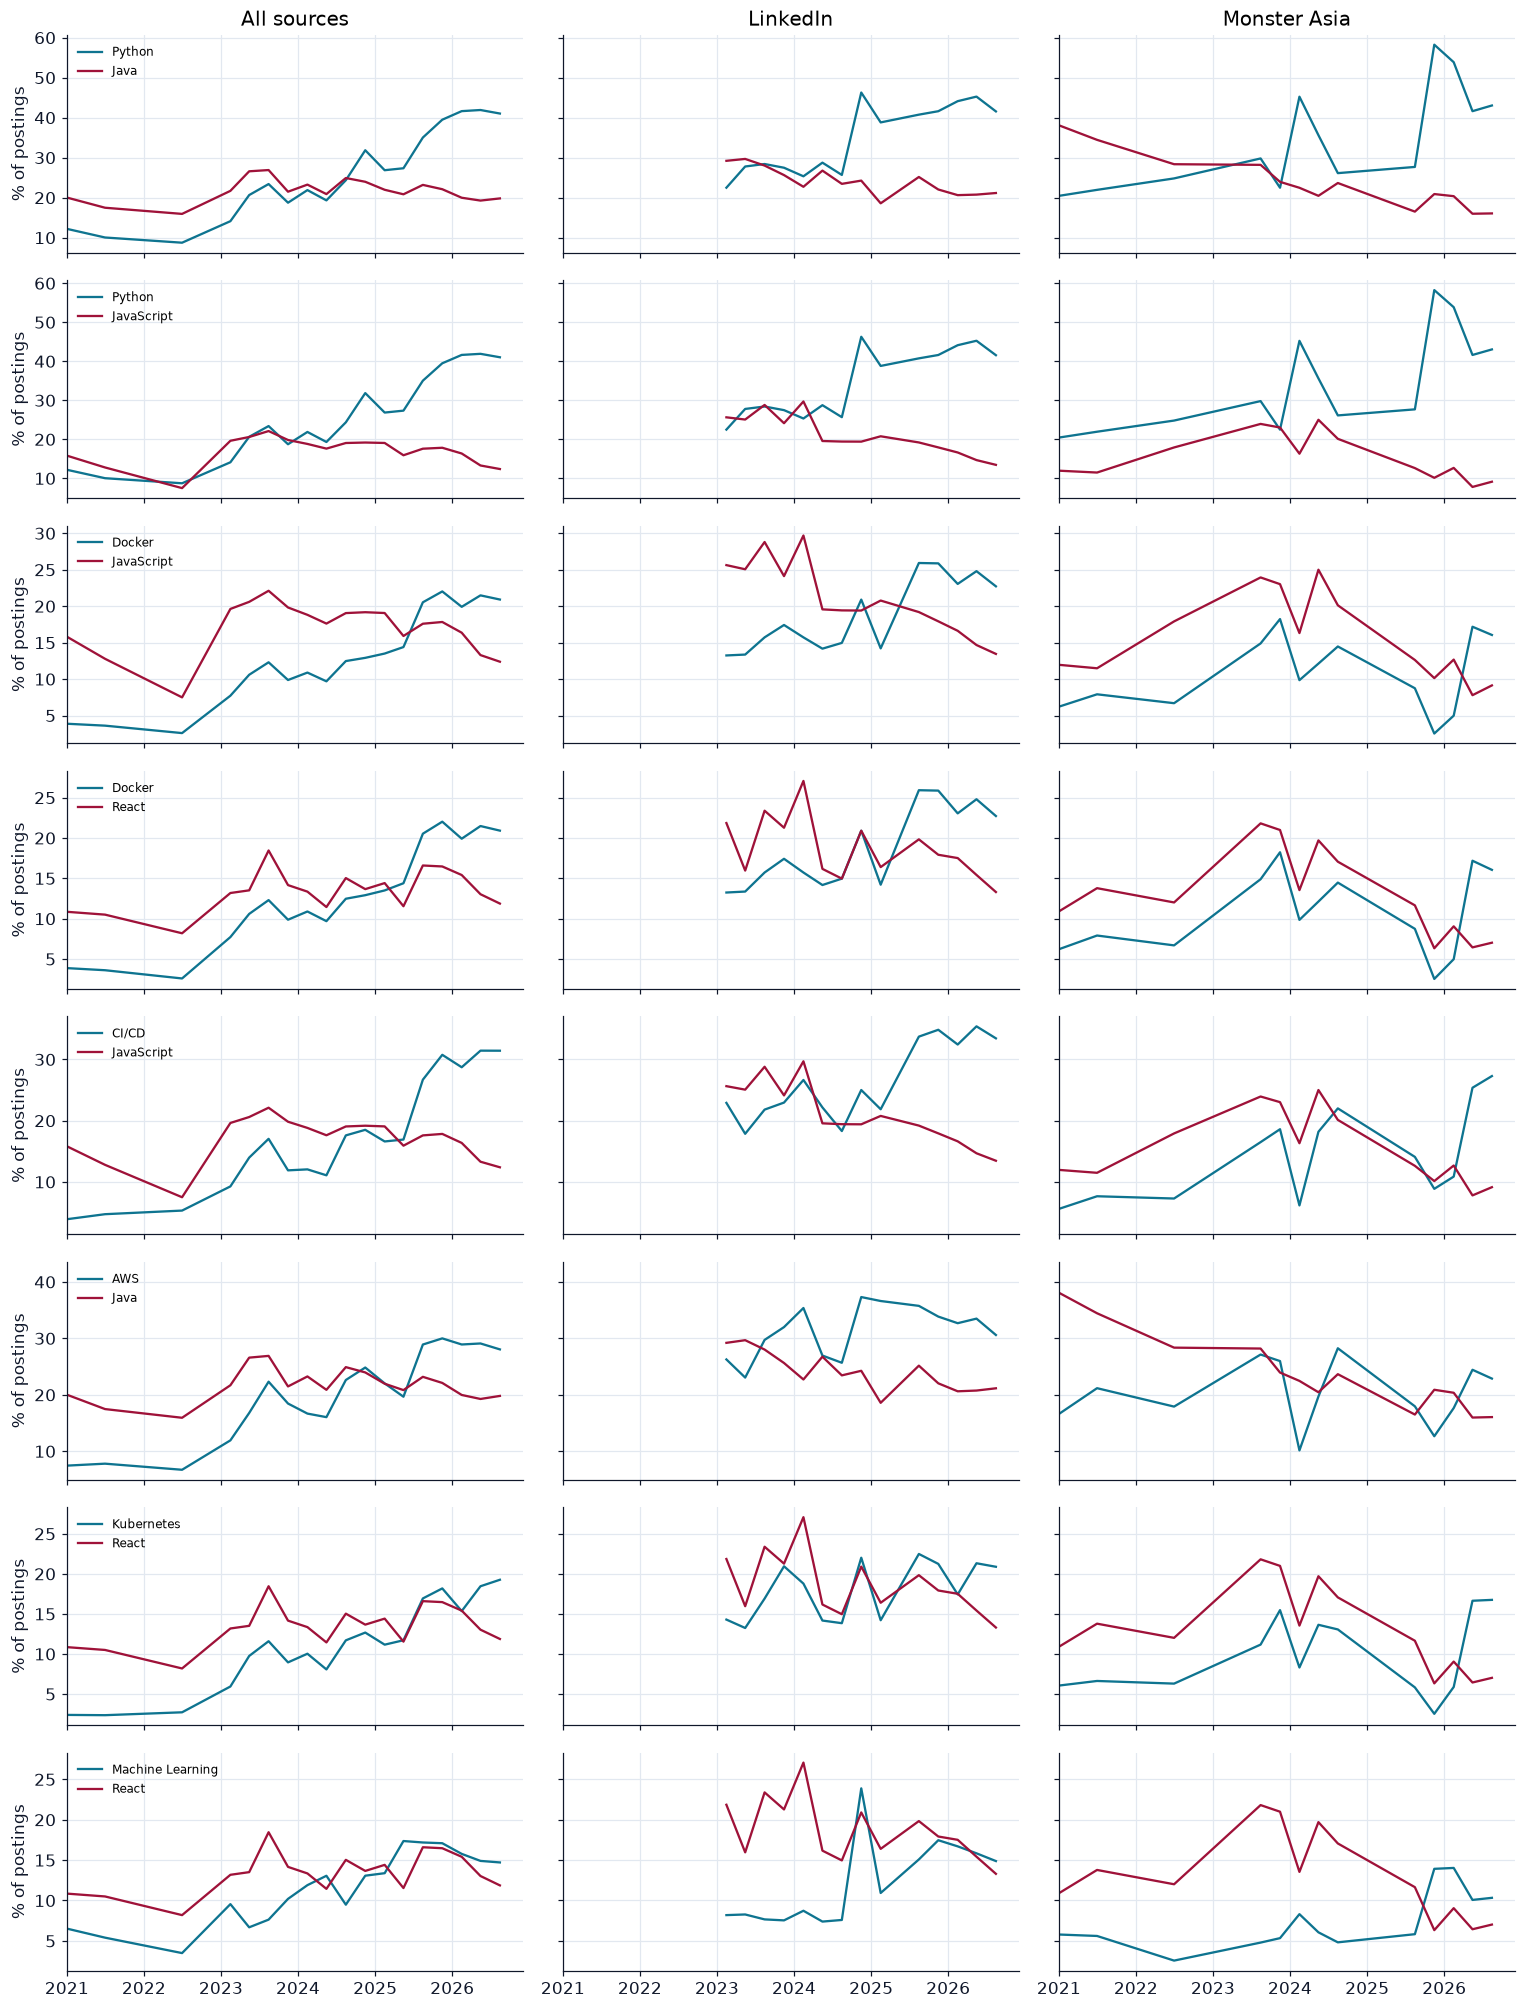

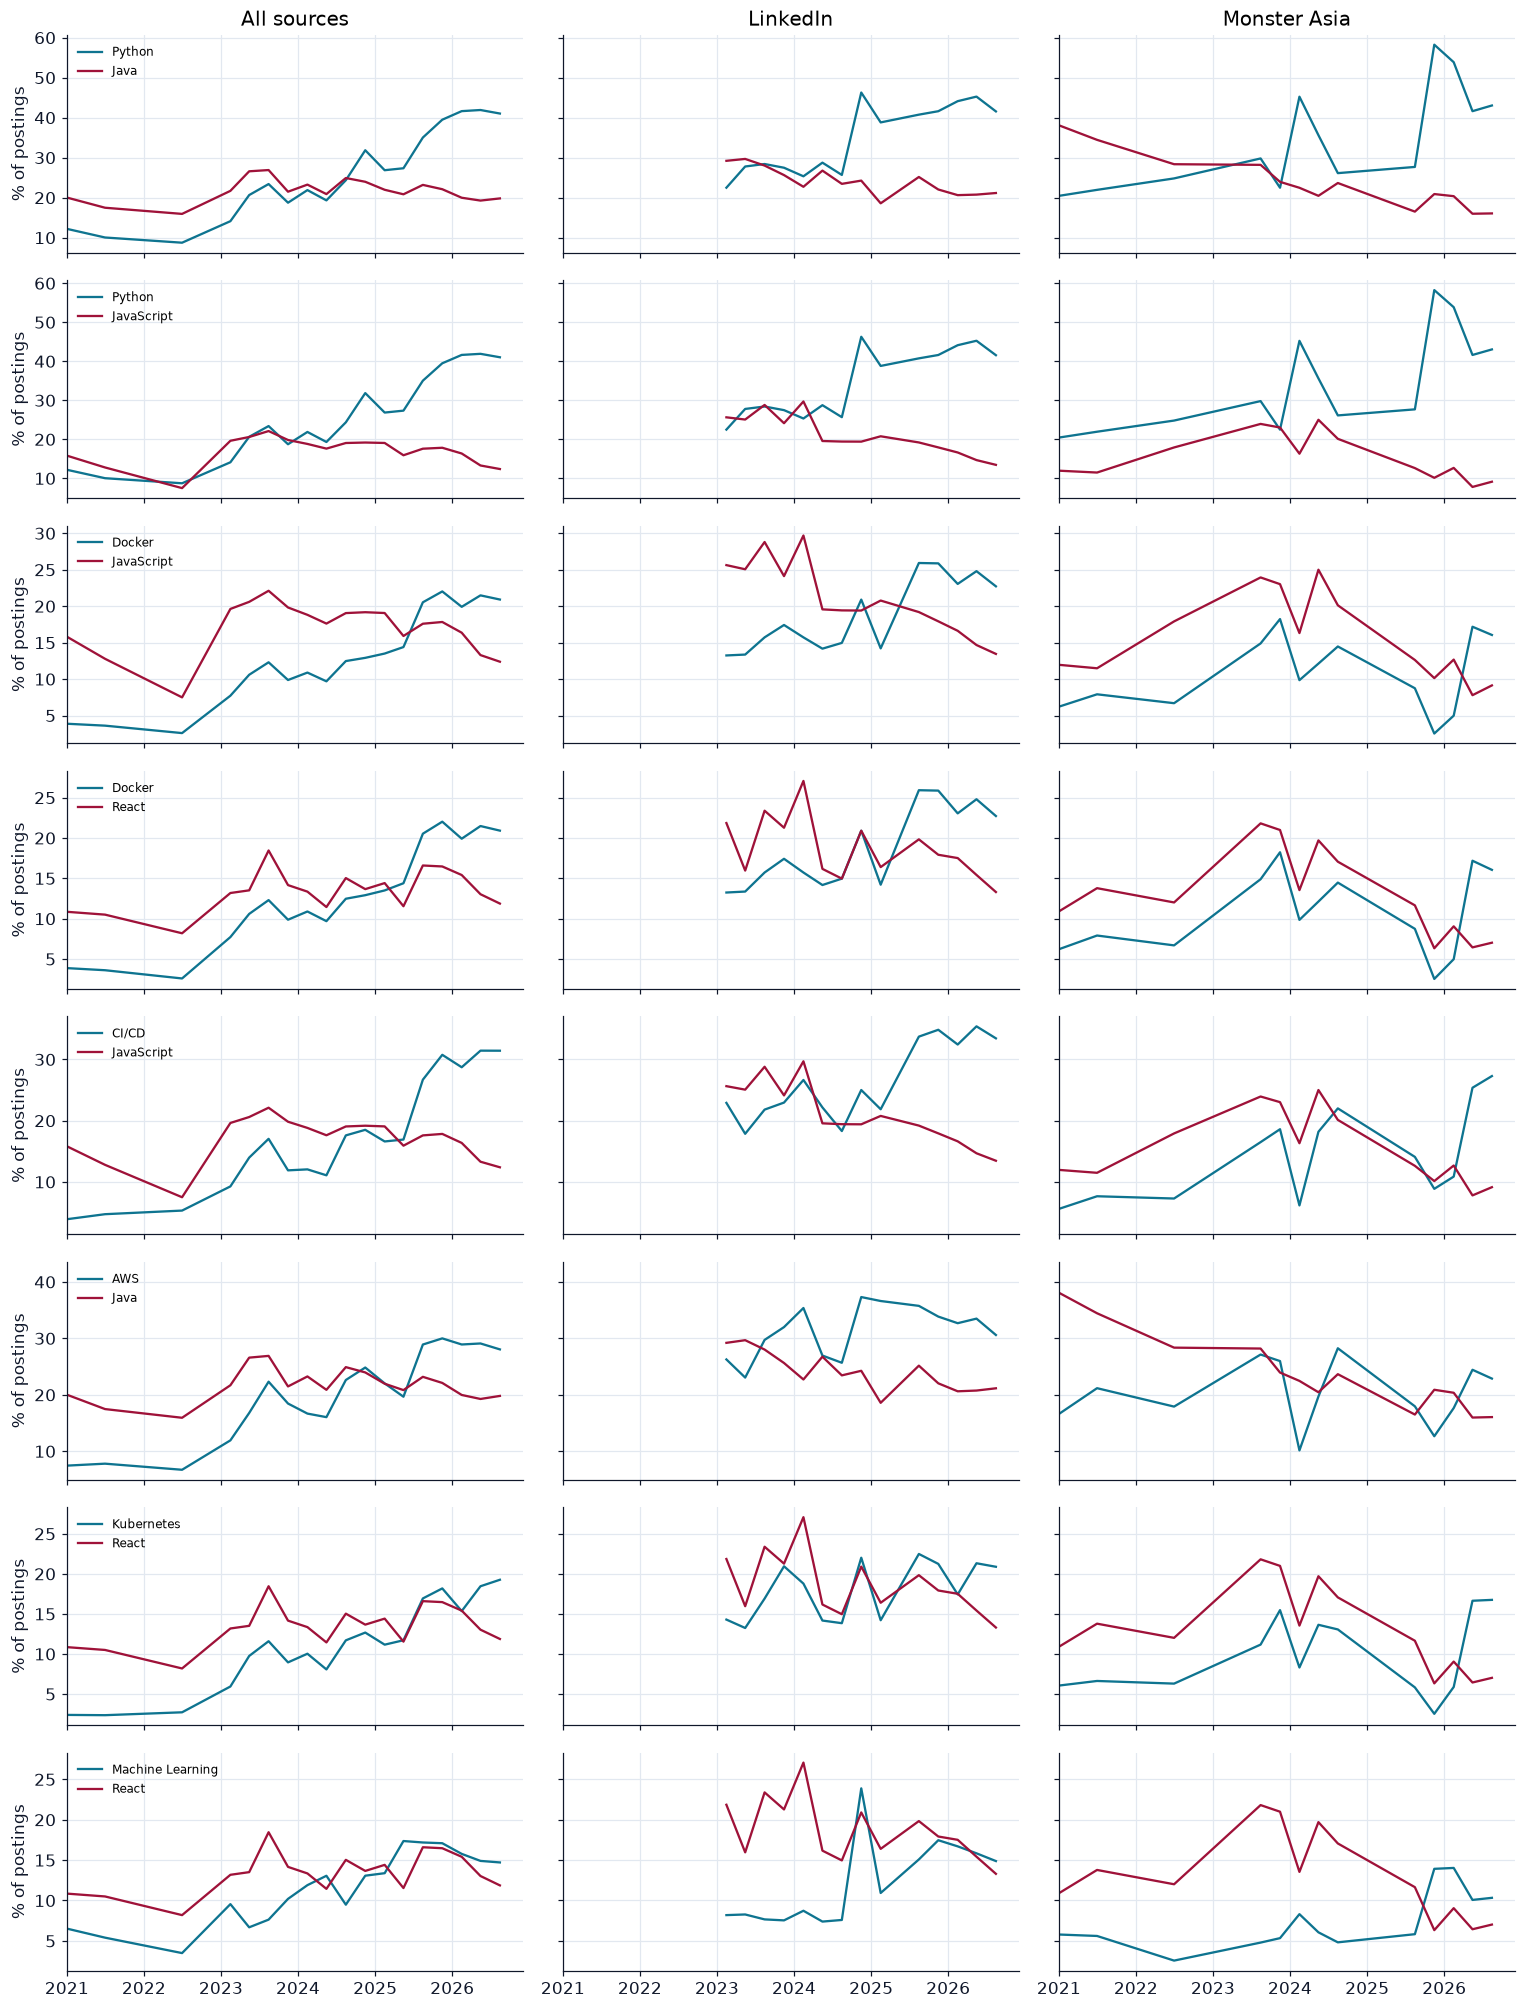

In [2]:
fig = c.chart_pairs(series)
a.save_chart(fig, "16-crossover-pairs")
fig

## 2. When each pair crossed, in each scope

In [3]:
table = c.crossover_table(series)
a.save_table(table, "16-crossover-by-scope")
table.pivot(index="pair", columns="scope", values="period")

scope,All sources,LinkedIn,Monster Asia
pair,,,
AWS > Java,2025-Q3,2024-Q3,2026-Q2
CI/CD > JavaScript,2025-Q3,2025-Q3,2026-Q2
Docker > JavaScript,2025-Q3,2025-Q3,2026-Q2
Docker > React,2025-Q2,2025-Q3,2026-Q2
Kubernetes > React,2026-Q2,2026-Q2,2026-Q2
Machine Learning > React,2026-Q3,,2025-Q4
Python > Java,2024-Q4,2024-Q3,2024-Q1
Python > JavaScript,2024-Q3,2024-Q2,2024-Q1


## 3. Which crossovers hold in both controls

In [4]:
agreement = c.agreement_table(series)
a.save_table(agreement, "16-crossover-agreement")
agreement

,pair,linkedin,monster_asia,all_sources,holds_in_both_controls
0,Python > Java,2024-Q3,2024-Q1,2024-Q4,True
1,Python > JavaScript,2024-Q2,2024-Q1,2024-Q3,True
2,Docker > JavaScript,2025-Q3,2026-Q2,2025-Q3,False
3,Docker > React,2025-Q3,2026-Q2,2025-Q2,False
4,CI/CD > JavaScript,2025-Q3,2026-Q2,2025-Q3,False
5,AWS > Java,2024-Q3,2026-Q2,2025-Q3,False
6,Kubernetes > React,2026-Q2,2026-Q2,2026-Q2,True
7,Machine Learning > React,never ahead,2025-Q4,2026-Q3,False


## Findings

1. **Two crossovers hold in both control sources, and both happen in 2024.** Python passes Java in 2024-Q3 on LinkedIn and 2024-Q1 on Monster Asia (all sources: 2024-Q4). Python passes JavaScript in 2024-Q2 on LinkedIn and 2024-Q1 on Monster Asia (all sources: 2024-Q3). The two controls are within two quarters of each other in both cases, so "Python took the lead during 2024" can be stated.
2. **The other dated crossovers do not hold.** Docker passes JavaScript and React (LinkedIn 2025-Q3), CI/CD passes JavaScript (LinkedIn 2025-Q3) and AWS passes Java (LinkedIn 2024-Q3), but Monster Asia dates all four in 2026-Q2. The direction agrees in both controls (each technology rises against the other) but the date does not, so these are stated as direction only, never as a year.
3. **Kubernetes passing React is too recent to call.** Both controls say 2026-Q2, but only two quarters lie behind it. Machine Learning passing React does not appear on LinkedIn at all (never ahead by 2 points).
4. **The rule matters.** With no margin, Python passes Java on LinkedIn in 2023-Q3, on a lead of about half a point. Python and Java sit within a point or two of each other for a year, so that date means nothing; the 2-point margin moves it to 2024-Q3. Python's LinkedIn share then steps up from roughly a quarter to roughly 45 % within one quarter (2024-Q4) rather than drifting, so the exact quarter of the lead rests on that step.
5. **Caveats.** Monster Asia has 100 to a few hundred tech-naming postings per quarter, so its lines are spiky (Python reaches 58 % in one quarter), which is why a crossover there is read together with LinkedIn's rather than alone. A technology named in a posting is a mention, not a count of jobs.

**What this notebook cannot say:** why a crossover happened, or that a technology is better. It can say when one overtook another on the two sources where the comparison is fair.